# ARTI 308 – Lab 5: Feature Engineering (Classification)
## Holiday Scope Prediction using a Global Public Holidays Dataset (2020–2026)

## 1. Setup and imports

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load the dataset

In [2]:
DATA_PATH = "global_public_holidays_2020_2026.csv"  # ensure the file is in the same folder as this notebook

# keep_default_na=False: Namibia's country code is "NA", which pandas would otherwise read as a missing value.
# na_values=[""]: only truly empty cells are treated as missing.
df = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""])

df.head(10)

,country_code,country_name,year,date,local_name,english_name,is_global,is_fixed_date,holiday_type,applicable_regions,launch_year
0,AL,Albania,2020,2020-01-01,Viti i Ri,New Year's Day,True,False,Public,All,NaN
1,AL,Albania,2020,2020-01-02,Viti i Ri,New Year's Day,True,False,Public,All,NaN
2,AL,Albania,2020,2020-03-16,Dita e Verës,Summer Day,True,False,Public,All,NaN
3,AL,Albania,2020,2020-03-23,Dita e Sulltan Nevruzit,Nowruz,True,False,Public,All,NaN
4,AL,Albania,2020,2020-04-12,Pashkët Katolike,Easter Sunday,True,False,Public,All,NaN
5,AL,Albania,2020,2020-04-13,E hëna e Pashkëve Katolike,Easter Monday,True,False,Public,All,NaN
6,AL,Albania,2020,2020-04-19,Pashkët Ortodokse,Easter Sunday,True,False,Public,All,NaN
7,AL,Albania,2020,2020-04-20,E hëna e Pashkëve Ortodokse,Easter Monday,True,False,Public,All,NaN
8,AL,Albania,2020,2020-05-01,Dita Ndërkombëtare e Punonjësve,May Day,True,False,Public,All,NaN
9,AL,Albania,2020,2020-09-07,Dita e Nënë Terezës,Mother Teresa Day,True,False,Public,All,NaN


## 3. Quick dataset checks

In [3]:
print("Shape:", df.shape)
print("\nMissing values per column:")
display(df.isna().sum().to_frame("missing_count").T)

print("\nDuplicate rows:", df.duplicated().sum())
print("\nUnique values per column:")
display(df.nunique().to_frame("n_unique").T)

Shape: (18597, 11)

Missing values per column:


,country_code,country_name,year,date,local_name,english_name,is_global,is_fixed_date,holiday_type,applicable_regions,launch_year
missing_count,0,0,0,0,0,0,0,0,0,0,18597



Duplicate rows: 3

Unique values per column:


,country_code,country_name,year,date,local_name,english_name,is_global,is_fixed_date,holiday_type,applicable_regions,launch_year
n_unique,204,204,7,2299,1436,766,2,1,13,141,0


In [4]:
df = df.drop_duplicates().reset_index(drop=True)
df = df.drop(columns=["launch_year", "is_fixed_date"])

print("Shape after cleaning:", df.shape)

Shape after cleaning: (18594, 9)


## 4. Target variable and class balance

In [5]:
target_col = "is_global"

# Convert True/False into readable labels
df[target_col] = df[target_col].map({True: "Global", False: "Regional"})
df[target_col].value_counts()

is_global
Global      17381
Regional     1213
Name: count, dtype: int64

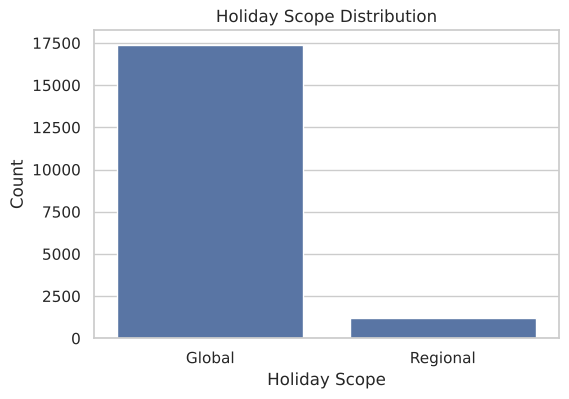

In [6]:
plt.figure(figsize=(6,4))
sns.countplot(x=target_col, data=df)
plt.title("Holiday Scope Distribution")
plt.xlabel("Holiday Scope")
plt.ylabel("Count")
plt.show()

## 5. Identify feature types

In [7]:
df.dtypes

country_code            str
country_name            str
year                  int64
date                    str
local_name              str
english_name            str
is_global               str
holiday_type            str
applicable_regions      str
dtype: object

## 6. Leakage awareness (important)

In [8]:
pd.crosstab(df["applicable_regions"] == "All", df[target_col])

is_global,Global,Regional
applicable_regions,,
False,0,1213
True,17381,0


## 7. Feature engineering

### 7.1 Time-based features from `date`

In [9]:
df_fe = df.copy()

df_fe["date"] = pd.to_datetime(df_fe["date"], errors="coerce")

df_fe["month"] = df_fe["date"].dt.month
df_fe["day"] = df_fe["date"].dt.day
df_fe["dayofweek"] = df_fe["date"].dt.dayofweek  # Monday=0, Sunday=6
df_fe["is_weekend"] = df_fe["dayofweek"].isin([5,6]).astype(int)
df_fe["is_end_of_year"] = df_fe["month"].isin([12,1]).astype(int)

df_fe[["date","month","day","dayofweek","is_weekend","is_end_of_year"]].head(10)

,date,month,day,dayofweek,is_weekend,is_end_of_year
0,2020-01-01,1,1,2,0,1
1,2020-01-02,1,2,3,0,1
2,2020-03-16,3,16,0,0,0
3,2020-03-23,3,23,0,0,0
4,2020-04-12,4,12,6,1,0
5,2020-04-13,4,13,0,0,0
6,2020-04-19,4,19,6,1,0
7,2020-04-20,4,20,0,0,0
8,2020-05-01,5,1,4,0,0
9,2020-09-07,9,7,0,0,0


### 7.2 Country-based features

In [10]:
df_fe["holidays_per_country_year"] = df_fe.groupby(["country_code","year"])["date"].transform("count")

df_fe[["country_code","year","holidays_per_country_year"]].drop_duplicates().head(10)

,country_code,year,holidays_per_country_year
0,AL,2020,14
14,AL,2021,14
28,AL,2022,13
41,AL,2023,13
54,AL,2024,14
68,AL,2025,14
82,AL,2026,14
96,DZ,2020,5
101,DZ,2021,5
106,DZ,2022,5


### 7.3 Name-based features from `english_name`

In [11]:
name = df_fe["english_name"].str.lower()

df_fe["name_length"] = name.str.len()
df_fe["name_word_count"] = name.str.split().str.len()

df_fe["is_saint_day"] = name.str.contains(r"\bsaint\b|\bst\.", regex=True).astype(int)

religious_words = ["easter", "christmas", "good friday", "ascension", "whit", "pentecost",
                   "corpus christi", "assumption", "all saints", "epiphany", "eid",
                   "ramadan", "diwali", "holy", "immaculate"]
df_fe["is_religious"] = name.str.contains("|".join(religious_words)).astype(int)

national_words = ["independence", "national", "republic", "constitution", "liberation", "unity", "victory"]
df_fe["is_national_day"] = name.str.contains("|".join(national_words)).astype(int)

df_fe[["english_name","name_length","is_saint_day","is_religious","is_national_day"]].head(10)

,english_name,name_length,is_saint_day,is_religious,is_national_day
0,New Year's Day,14,0,0,0
1,New Year's Day,14,0,0,0
2,Summer Day,10,0,0,0
3,Nowruz,6,0,0,0
4,Easter Sunday,13,0,1,0
5,Easter Monday,13,0,1,0
6,Easter Sunday,13,0,1,0
7,Easter Monday,13,0,1,0
8,May Day,7,0,0,0
9,Mother Teresa Day,17,0,0,0


### 7.4 Reducing high-cardinality categories

In [12]:
top_k = 30
top_countries = df_fe["country_code"].value_counts().head(top_k).index
df_fe["country_reduced"] = np.where(df_fe["country_code"].isin(top_countries), df_fe["country_code"], "Other")

df_fe["primary_type"] = df_fe["holiday_type"].str.split(",").str[0].str.strip()
df_fe["has_multiple_types"] = df_fe["holiday_type"].str.contains(",").astype(int)

print("Unique country_code:", df_fe["country_code"].nunique())
print("Unique country_reduced:", df_fe["country_reduced"].nunique())
print("Unique holiday_type:", df_fe["holiday_type"].nunique())
print("Unique primary_type:", df_fe["primary_type"].nunique())

Unique country_code: 204
Unique country_reduced: 31
Unique holiday_type: 13
Unique primary_type: 6


## 8. Discretization (binning)

In [13]:
df_fe["holiday_load_tier"] = pd.cut(
    df_fe["holidays_per_country_year"],
    bins=[0, 10, 15, 20, np.inf],
    labels=["few","average","many","very_many"]
)

df_fe["holiday_load_tier"].value_counts()

holiday_load_tier
average      9892
many         3349
few          2825
very_many    2528
Name: count, dtype: int64

## 9. Prepare features for modeling

In [14]:
drop_cols = [
    "applicable_regions",                      # leakage
    "country_code", "country_name",            # replaced by country_reduced
    "local_name", "english_name",              # replaced by name-based features
    "holiday_type",                            # replaced by primary_type
    "date", "year"
]
drop_cols = [c for c in drop_cols if c in df_fe.columns]

X = df_fe.drop(columns=drop_cols + [target_col])
y = df_fe[target_col]

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (18594, 15)
y shape: (18594,)


,month,day,dayofweek,is_weekend,is_end_of_year,holidays_per_country_year,name_length,name_word_count,is_saint_day,is_religious,is_national_day,country_reduced,primary_type,has_multiple_types,holiday_load_tier
0,1,1,2,0,1,14,14,3,0,0,0,Other,Public,0,average
1,1,2,3,0,1,14,14,3,0,0,0,Other,Public,0,average
2,3,16,0,0,0,14,10,2,0,0,0,Other,Public,0,average
3,3,23,0,0,0,14,6,1,0,0,0,Other,Public,0,average
4,4,12,6,1,0,14,13,2,0,1,0,Other,Public,0,average


## 10. Split into train and test sets

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (14875, 15)
Test size: (3719, 15)


## 11. Encoding and baseline model (Random Forest)

In [16]:
categorical_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()
numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)

preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols),
    ]
)

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced_subsample"
)

model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("rf", rf)
])

model

Categorical columns: ['country_reduced', 'primary_type', 'holiday_load_tier']
Numeric columns: ['month', 'day', 'dayofweek', 'is_weekend', 'is_end_of_year', 'holidays_per_country_year', 'name_length', 'name_word_count', 'is_saint_day', 'is_religious', 'is_national_day', 'has_multiple_types']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('rf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the outp

## 12. Train the model and evaluate

In [17]:
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9898

Classification Report:
              precision    recall  f1-score   support

      Global       1.00      0.99      0.99      3476
    Regional       0.91      0.94      0.92       243

    accuracy                           0.99      3719
   macro avg       0.95      0.97      0.96      3719
weighted avg       0.99      0.99      0.99      3719



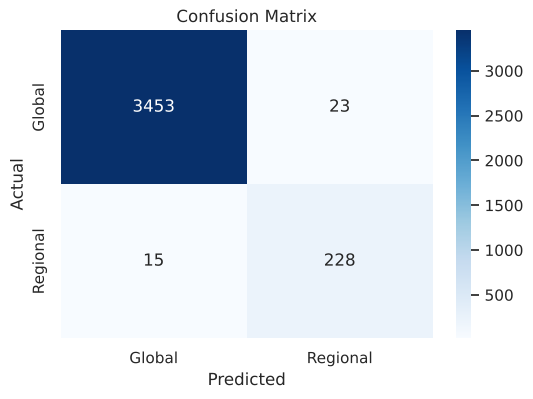

In [18]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 13. Feature importance (What mattered the most?)

In [19]:
ohe = model.named_steps["preprocess"].named_transformers_["cat"]
cat_feature_names = ohe.get_feature_names_out(categorical_cols)
all_feature_names = np.concatenate([cat_feature_names, np.array(numeric_cols)])

importances = model.named_steps["rf"].feature_importances_

fi = (pd.DataFrame({"feature": all_feature_names, "importance": importances})
        .sort_values("importance", ascending=False))

fi.head(15)

,feature,importance
46,holidays_per_country_year,0.248938
20,country_reduced_Other,0.093329
40,holiday_load_tier_very_many,0.092506
47,name_length,0.073927
42,day,0.057396
41,month,0.046506
37,holiday_load_tier_average,0.037594
48,name_word_count,0.030634
43,dayofweek,0.022943
38,holiday_load_tier_few,0.022001


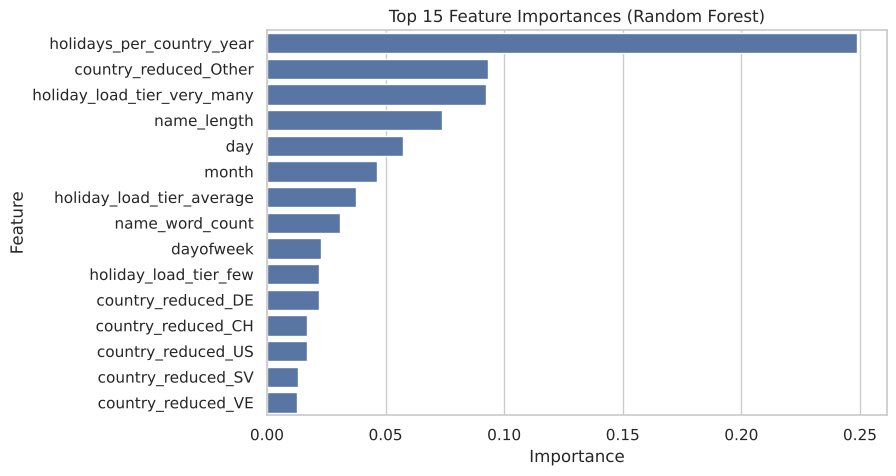

In [20]:
plt.figure(figsize=(8,5))
top_n = 15
sns.barplot(data=fi.head(top_n), x="importance", y="feature")
plt.title(f"Top {top_n} Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## 14. Optional: Feature selection using SelectFromModel

In [21]:
from sklearn.feature_selection import SelectFromModel

selector = SelectFromModel(
    estimator=RandomForestClassifier(
        n_estimators=300, random_state=42, n_jobs=-1, class_weight="balanced_subsample"
    ),
    threshold="median"  # keep features above the median importance
)

model_fs = Pipeline(steps=[
    ("preprocess", preprocess),
    ("select", selector),
    ("rf", RandomForestClassifier(
        n_estimators=300, random_state=42, n_jobs=-1, class_weight="balanced_subsample"
    ))
])

model_fs.fit(X_train, y_train)
y_pred_fs = model_fs.predict(X_test)

print("Accuracy (with feature selection):", round(accuracy_score(y_test, y_pred_fs), 4))
print("\nClassification Report (with feature selection):")
print(classification_report(y_test, y_pred_fs))

Accuracy (with feature selection): 0.9909

Classification Report (with feature selection):
              precision    recall  f1-score   support

      Global       1.00      0.99      1.00      3476
    Regional       0.91      0.95      0.93       243

    accuracy                           0.99      3719
   macro avg       0.95      0.97      0.96      3719
weighted avg       0.99      0.99      0.99      3719



## 15. Time-based split

In [22]:
train_mask = df_fe["year"] <= 2024

X_train_t, X_test_t = X[train_mask], X[~train_mask]
y_train_t, y_test_t = y[train_mask], y[~train_mask]

print("Train (2020-2024):", X_train_t.shape, " Test (2025-2026):", X_test_t.shape)

model.fit(X_train_t, y_train_t)
y_pred_t = model.predict(X_test_t)

print("\nAccuracy (time-based split):", round(accuracy_score(y_test_t, y_pred_t), 4))
print("\nClassification Report (time-based split):")
print(classification_report(y_test_t, y_pred_t))

Train (2020-2024): (13265, 15)  Test (2025-2026): (5329, 15)



Accuracy (time-based split): 0.9925

Classification Report (time-based split):
              precision    recall  f1-score   support

      Global       1.00      1.00      1.00      4982
    Regional       0.93      0.95      0.94       347

    accuracy                           0.99      5329
   macro avg       0.96      0.97      0.97      5329
weighted avg       0.99      0.99      0.99      5329

